# 06 - Model Comparison, Validation Gap Analysis, and Error Diagnostics

### Research Question
How do prediction error estimates (RMSE, MAE, R², RMSLE) obtained with random k-fold cross-validation differ from those obtained with chronological validation, in which direction and by how much, and does the magnitude of this difference vary across the tested model families and their variants?

### Structure of this Notebook
1. **Fold-averaged summary**: benchmarks of all models and schemes, as saved by the model notebooks.
2. **Matched 2012 evaluation**: all schemes scored on the identical hours that the chronological scheme tests.
3. **Validation gap**: absolute and relative RMSE increase from random to chronological validation, with block-bootstrap uncertainty.
4. **Diagnostics**: error by test period, residuals against predictions, bias over time, peak versus off-peak hours.
5. **Conclusions and limitations.**

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src.data import load_data
from src.validation import RESULTS_DIR, SCHEMES, SEED, compute_metrics

# the notebook indexes schemes by these literal names, so fail early if they ever change
assert set(SCHEMES) == {"random", "blocked", "chrono"}, SCHEMES

plt.style.use("default")               # reset any inherited theme (e.g. a dark one)
Path("figures").mkdir(exist_ok=True)   # figures are saved here

## 0. Loading the Results

Every model notebook saves `results/{model}_{scheme}_folds.csv` and `results/{model}_{scheme}_preds.csv`. This notebook trains nothing; it only reads them. If any file is missing, loading stops with the list of missing files instead of silently leaving a model out of the figures.

In [2]:
MODELS = ["baseline_const", "baseline_hour_day", "ridge", "ridge_log", "rf", "hgb", "hgb_poisson"]
NAMES = {
    "baseline_const": "Baseline: constant", "baseline_hour_day": "Baseline: hour × day type",
    "ridge": "Ridge", "ridge_log": "Ridge (log target)", "rf": "Random forest",
    "hgb": "Boosting (squared error)", "hgb_poisson": "Boosting (Poisson)",
}

missing = [f"{m}_{s}_{kind}.csv" for m in MODELS for s in SCHEMES for kind in ("folds", "preds")
           if not (RESULTS_DIR / f"{m}_{s}_{kind}.csv").exists()]
if missing:
    raise FileNotFoundError("Missing result files (run the model notebooks or git pull):\n" + "\n".join(missing))

folds = {(m, s): pd.read_csv(RESULTS_DIR / f"{m}_{s}_folds.csv", parse_dates=["test_start", "test_end"])
         for m in MODELS for s in SCHEMES}
preds = {(m, s): pd.read_csv(RESULTS_DIR / f"{m}_{s}_preds.csv", index_col="datetime", parse_dates=True)
         for m in MODELS for s in SCHEMES}

fold_cols = ["fold", "n_train", "n_test", "test_start", "test_end"]

for scheme in SCHEMES:
    reference = folds[(MODELS[0], scheme)][fold_cols].reset_index(drop=True)

    for model in MODELS[1:]:
        current = folds[(model, scheme)][fold_cols].reset_index(drop=True)
        pd.testing.assert_frame_equal(reference, current, check_dtype=False)

print("All models use identical outer fold boundaries.")

print(f"Loaded {len(MODELS)} models x {len(SCHEMES)} schemes")

All models use identical outer fold boundaries.
Loaded 7 models x 3 schemes


## 1. Fold-Averaged Summary

*Random and blocked validation test on all hours of 2011-2012, whereas chronological validation tests only on 2012, so these fold averages compare models within one scheme; they do not measure the validation gap (see Section 2).*

In [3]:
metric_cols = ["rmse_mean", "rmse_std", "mae_mean", "r2_mean", "rmsle_mean"]
summary = pd.DataFrame([{
    "model": m, "scheme": s,
    "rmse_mean": folds[(m, s)]["rmse"].mean(), "rmse_std": folds[(m, s)]["rmse"].std(),
    "mae_mean": folds[(m, s)]["mae"].mean(), "r2_mean": folds[(m, s)]["r2"].mean(), "rmsle_mean": folds[(m, s)]["rmsle"].mean(),
} for m in MODELS for s in SCHEMES])

summary_wide = (summary.pivot(index="model", columns="scheme")[metric_cols]
                .reindex(columns=pd.MultiIndex.from_product([metric_cols, SCHEMES]))
                .reindex(MODELS))
summary_wide.round(2)

rmse_mean                 rmse_std                mae_mean  \
                     random blocked  chrono   random blocked chrono   random   
model                                                                          
baseline_const       181.37  182.12  215.61     3.54   47.23  52.74   142.41   
baseline_hour_day    109.94  119.11  133.29     1.38   38.85  44.82    72.96   
ridge                 89.10  117.73  126.88     1.25   21.52  23.50    65.32   
ridge_log             81.48  119.32  128.33     0.93   26.88  15.14    52.27   
rf                    65.81  114.13  117.11     2.00   14.55  11.55    42.95   
hgb                   64.71  114.69  120.69     1.28   13.16  12.74    43.19   
hgb_poisson           62.98  114.97  121.37     1.22   12.75  11.91    41.21   

                                  r2_mean                rmsle_mean          \
                  blocked  chrono  random blocked chrono     random blocked   
model                                                                         
baseline_const     147.17  165.45   -0.00   -0.28  -0.16       1.57    1.58   
baseline_hour_day   83.46   95.48    0.63    0.30   0.56       0.65    0.66   
ridge               90.94   96.43    0.76    0.41   0.59       1.00    1.11   
ridge_log           82.21   90.98    0.80    0.45   0.56       0.43    0.58   
rf                  80.59   83.15    0.87    0.45   0.63       0.42    0.56   
hgb                 83.37   87.24    0.87    0.44   0.61       0.49    0.66   
hgb_poisson         82.75   87.16    0.88    0.44   0.60       0.38    0.59   

                          
                  chrono  
model                     
baseline_const      1.44  
baseline_hour_day   0.58  
ridge               1.10  
ridge_log           0.57  
rf                  0.51  
hgb                 0.61  
hgb_poisson         0.52

## 2. Matched Evaluation on Identical 2012 Hours

The three validation schemes do not naturally evaluate the same observations. Chronological validation tests only on 2012, so we restrict the out-of-fold predictions from random and blocked validation to exactly the timestamps evaluated by the chronological scheme.

This produces a common test set of 8,722 observations from 2012. Using identical test timestamps makes the evaluation metrics comparable with respect to the test period.

However, the training sets are not identical. Random and blocked validation may use observations later than the corresponding test timestamps, whereas chronological validation uses only earlier observations. Therefore, differences between schemes reflect both the validation design and the amount and temporal composition of the available training data.

The code below verifies that all models and schemes have predictions for the same timestamps and that the actual target values (`y_true`) agree across them.

`bias` is the mean residual (actual - predicted): positive values indicate underestimation, while negative values indicate overestimation.

In [4]:
chrono_index = preds[(MODELS[0], "chrono")].index

assert chrono_index.is_unique
assert chrono_index.is_monotonic_increasing

reference_y = preds[(MODELS[0], "chrono")].loc[chrono_index, "y_true"]

for (model, scheme), p in preds.items():
    assert p.index.is_unique, f"Duplicate timestamps: {model}, {scheme}"

    if scheme == "chrono":
        assert p.index.equals(chrono_index), f"Chronological timestamps differ: {model}"
    else:
        assert chrono_index.isin(p.index).all(), f"Missing timestamps: {model}, {scheme}"

    current_y = p.loc[chrono_index, "y_true"]
    assert np.allclose(current_y, reference_y), f"Different y_true: {model}, {scheme}"

print("All models and schemes have identical actual target values on the matched timestamps.")

matched = {key: p.loc[chrono_index] for key, p in preds.items()}
print(f"Matched set: {len(chrono_index):,} hours, {chrono_index.min():%Y-%m-%d} to {chrono_index.max():%Y-%m-%d}")

rows = []
for (m, s), p in matched.items():
    rows.append({"model": m, "scheme": s, "bias": (p["y_true"] - p["y_pred"]).mean(),
                 **compute_metrics(p["y_true"], p["y_pred"])})
df_matched = pd.DataFrame(rows)


def wide(metric):
    return df_matched.pivot(index="model", columns="scheme", values=metric)[list(SCHEMES)].reindex(MODELS)


rmse_matched, mae_matched, bias_matched = wide("rmse"), wide("mae"), wide("bias")

print("\nRMSE on matched hours")
display(rmse_matched.round(1))
print("MAE on matched hours")
display(mae_matched.round(1))
print("Bias (mean residual) on matched hours")
display(bias_matched.round(1))

All models and schemes have identical actual target values on the matched timestamps.
Matched set: 8,722 hours, 2012-01-01 to 2012-12-31

RMSE on matched hours


scheme,random,blocked,chrono
model,,,
baseline_const,213.8,219.0,220.9
baseline_hour_day,120.0,134.0,139.4
ridge,96.3,126.6,128.7
ridge_log,94.3,136.2,129.1
rf,71.3,120.5,117.6
hgb,68.3,119.0,121.3
hgb_poisson,67.2,121.2,121.9


MAE on matched hours


scheme,random,blocked,chrono
model,,,
baseline_const,164.3,167.1,165.6
baseline_hour_day,82.4,93.7,95.6
ridge,69.7,92.4,96.5
ridge_log,63.0,93.6,91.0
rf,45.3,82.3,83.2
hgb,45.7,84.7,87.3
hgb_poisson,44.1,85.8,87.2


Bias (mean residual) on matched hours


scheme,random,blocked,chrono
model,,,
baseline_const,45.5,56.4,72.9
baseline_hour_day,46.2,57.0,73.6
ridge,41.3,76.4,82.6
ridge_log,52.7,89.7,86.6
rf,31.0,74.2,76.8
hgb,32.5,78.8,81.8
hgb_poisson,32.6,80.6,82.4


**Remaining metrics.** The research question also names R² and RMSLE, so they are reported here on the same matched hours (the table above shows RMSE, MAE and bias only).

In [5]:
print("Metric columns returned by compute_metrics:",
      [c for c in df_matched.columns if c not in ("model", "scheme", "bias")])
for metric in [c for c in ("r2", "rmsle") if c in df_matched.columns]:
    print(f"\n{metric.upper()} on matched hours")
    display(wide(metric).round(3))

Metric columns returned by compute_metrics: ['rmse', 'mae', 'r2', 'rmsle']

R2 on matched hours


scheme,random,blocked,chrono
model,,,
baseline_const,-0.048,-0.099,-0.118
baseline_hour_day,0.670,0.589,0.555
ridge,0.788,0.633,0.620
ridge_log,0.796,0.575,0.618
rf,0.884,0.668,0.683
hgb,0.893,0.676,0.663
hgb_poisson,0.897,0.664,0.660



RMSLE on matched hours


scheme,random,blocked,chrono
model,,,
baseline_const,1.486,1.481,1.445
baseline_hour_day,0.536,0.581,0.583
ridge,0.999,1.145,1.175
ridge_log,0.420,0.564,0.576
rf,0.356,0.502,0.515
hgb,0.434,0.628,0.622
hgb_poisson,0.333,0.521,0.532


## 3. The Validation Gap

$$\Delta \text{RMSE} = \text{RMSE}_{\text{chrono}} - \text{RMSE}_{\text{random}}, \qquad \% \text{ gap} = \frac{\Delta \text{RMSE}}{\text{RMSE}_{\text{random}}} \times 100$$

A single RMSE per cell hides how much it would change with a different sample of test hours. Neighbouring hours are strongly correlated, so ordinary confidence intervals would be too narrow. We therefore use a **block bootstrap over calendar weeks**: whole weeks of the matched set are resampled with replacement, and the same resampled weeks are used for every model and scheme (so comparisons between them are paired). The intervals describe the uncertainty from the choice of test hours only; they do not include the randomness of training or of the hyperparameter search.

In [6]:
try:
    CLIP = bool(np.isclose(compute_metrics(pd.Series([10.0, 20.0]), pd.Series([-5.0, 20.0]))["rmse"], np.sqrt(50.0)))
except Exception as exc:
    CLIP = False
    print("clip probe failed, assuming no clipping:", exc)

N_BOOT = 2000
week_id = pd.factorize(chrono_index.to_period("W"))[0]
n_weeks = week_id.max() + 1
week_counts = np.bincount(week_id, minlength=n_weeks)
draw = np.random.default_rng(SEED).integers(0, n_weeks, size=(N_BOOT, n_weeks))  # same weeks for all models

boot_rmse = {}
for key, p in matched.items():
    pred = p["y_pred"].clip(lower=0) if CLIP else p["y_pred"]
    week_sq_err = np.bincount(week_id, weights=((p["y_true"] - pred) ** 2).to_numpy(), minlength=n_weeks)
    boot_rmse[key] = np.sqrt(week_sq_err[draw].sum(axis=1) / week_counts[draw].sum(axis=1))


def ci(values):
    return np.percentile(values, [2.5, 97.5])


gap = pd.DataFrame({
    "random": rmse_matched["random"], "blocked": rmse_matched["blocked"], "chrono": rmse_matched["chrono"],
})
gap["delta"] = gap["chrono"] - gap["random"]
gap["gap_pct"] = gap["delta"] / gap["random"] * 100
boot_gap = {m: (boot_rmse[(m, "chrono")] / boot_rmse[(m, "random")] - 1) * 100 for m in MODELS}
gap["gap_pct_low"] = [ci(boot_gap[m])[0] for m in MODELS]
gap["gap_pct_high"] = [ci(boot_gap[m])[1] for m in MODELS]
display(gap.round(1))

# improvement over the hour x day type baseline, per scheme
gain = (1 - rmse_matched.div(rmse_matched.loc["baseline_hour_day"])) * 100
print("RMSE improvement over the hour x day type baseline (%)")
display(gain.round(1))

,random,blocked,chrono,delta,gap_pct,gap_pct_low,gap_pct_high
model,,,,,,,
baseline_const,213.8,219.0,220.9,7.1,3.3,2.3,4.1
baseline_hour_day,120.0,134.0,139.4,19.4,16.2,11.4,20.5
ridge,96.3,126.6,128.7,32.4,33.7,29.6,37.7
ridge_log,94.3,136.2,129.1,34.9,37.0,33.3,40.9
rf,71.3,120.5,117.6,46.3,65.0,57.7,72.7
hgb,68.3,119.0,121.3,53.0,77.5,69.4,86.2
hgb_poisson,67.2,121.2,121.9,54.7,81.5,72.8,91.1


RMSE improvement over the hour x day type baseline (%)


scheme,random,blocked,chrono
model,,,
baseline_const,-78.2,-63.4,-58.5
baseline_hour_day,0.0,0.0,0.0
ridge,19.7,5.5,7.6
ridge_log,21.4,-1.6,7.4
rf,40.6,10.1,15.6
hgb,43.1,11.2,13.0
hgb_poisson,44.0,9.6,12.5


### 3.1 The gap in other metrics, and sensitivity to the bootstrap block

Two checks on Section 3. (1) Is the gap specific to RMSE? RMSE is dominated by the largest errors, so MAE and RMSLE (which weights relative errors) are bootstrapped the same way. (2) Does the interval depend on the choice of resampling unit? Whole weeks were used above; days and two-week blocks are tried here. If the intervals barely move, the conclusion does not hinge on that choice.

Every metric is rebuilt from per-block sums of errors, so the same resampled blocks are used for all models and schemes. The first printout confirms that these sums reproduce the point estimates from `compute_metrics`.

In [7]:
def block_ids(index, block="W"):
    """Integer block label per hour: calendar day (D), week (W) or pair of weeks (2W)."""
    weeks = pd.factorize(index.to_period("W"))[0]
    if block == "W":
        return weeks
    if block == "2W":
        return weeks // 2
    if block == "D":
        return pd.factorize(index.to_period("D"))[0]
    raise ValueError(block)


def block_sums(p, bid, n_blocks, clip=False):
    """Per-block sufficient statistics: counts, squared errors, absolute errors, squared log errors."""
    y, f = p["y_true"].to_numpy(float), p["y_pred"].to_numpy(float)
    if clip:                       # same convention as compute_metrics, if it clips negative predictions
        f = np.clip(f, 0, None)
    e = y - f
    sle = (np.log1p(y) - np.log1p(np.clip(f, 0, None))) ** 2   # predictions clipped at 0 for the log
    add = lambda v: np.bincount(bid, weights=v, minlength=n_blocks)
    return {"n": np.bincount(bid, minlength=n_blocks).astype(float),
            "se": add(e ** 2), "ae": add(np.abs(e)), "sle": add(sle)}


def metric_from_sums(name, s, d=None):
    """Metric from block sums; d = array of resampled block indices (n_boot x n_blocks), None = full sample."""
    tot = (lambda k: s[k][d].sum(axis=1)) if d is not None else (lambda k: s[k].sum())
    if name == "rmse":
        return np.sqrt(tot("se") / tot("n"))
    if name == "mae":
        return tot("ae") / tot("n")
    if name == "rmsle":
        return np.sqrt(tot("sle") / tot("n"))
    raise ValueError(name)


print("compute_metrics clips predictions at 0 (probe from Section 3):", CLIP)


def gap_table(block="W", n_boot=N_BOOT):
    bid = block_ids(chrono_index, block)
    nb = bid.max() + 1
    d = np.random.default_rng(SEED).integers(0, nb, size=(n_boot, nb))   # same blocks for every model and scheme
    sums = {key: block_sums(p, bid, nb, CLIP) for key, p in matched.items()}
    rows = []
    for m in MODELS:
        for metric in ("rmse", "mae", "rmsle"):
            point = {s: metric_from_sums(metric, sums[(m, s)]) for s in SCHEMES}
            boot = {s: metric_from_sums(metric, sums[(m, s)], d) for s in SCHEMES}
            low, high = np.percentile((boot["chrono"] / boot["random"] - 1) * 100, [2.5, 97.5])
            rows.append({"model": m, "metric": metric, "random": point["random"], "blocked": point["blocked"],
                         "chrono": point["chrono"], "gap_pct": (point["chrono"] / point["random"] - 1) * 100,
                         "low": low, "high": high})
    return pd.DataFrame(rows)


gap_all = gap_table("W")

# sanity check: block sums must reproduce compute_metrics (differences should be ~0)
chk = gap_all[gap_all["metric"] == "rmse"].set_index("model")["chrono"]
print("max |RMSE(sums) - RMSE(compute_metrics)| =", float((chk - rmse_matched["chrono"]).abs().max()))
for metric in ("mae", "rmsle"):
    if metric in df_matched.columns:
        ref = wide(metric)["chrono"]
        mine = gap_all[gap_all["metric"] == metric].set_index("model")["chrono"]
        print(f"max |{metric.upper()}(sums) - {metric.upper()}(compute_metrics)| =", float((mine - ref).abs().max()))


def fmt(row):
    return f"{row.gap_pct:+.0f}% [{row.low:+.0f}, {row.high:+.0f}]"


print("\nGap chronological vs random (%), point estimate and 95% block-bootstrap interval")
display(gap_all.assign(txt=gap_all.apply(fmt, axis=1)).pivot(index="model", columns="metric", values="txt")
        .reindex(MODELS)[["rmse", "mae", "rmsle"]])

print("RMSE gap (%) under different bootstrap blocks")
robust = {blk: gap_table(blk).query("metric == 'rmse'").set_index("model") for blk in ("D", "W", "2W")}
display(pd.DataFrame({f"block={blk}": robust[blk].apply(fmt, axis=1) for blk in robust}).reindex(MODELS))

compute_metrics clips predictions at 0 (probe from Section 3): False
max |RMSE(sums) - RMSE(compute_metrics)| = 2.842170943040401e-14
max |MAE(sums) - MAE(compute_metrics)| = 2.842170943040401e-14
max |RMSLE(sums) - RMSLE(compute_metrics)| = 4.440892098500626e-16

Gap chronological vs random (%), point estimate and 95% block-bootstrap interval


metric,rmse,mae,rmsle
model,,,
baseline_const,"+3% [+2, +4]","+1% [-1, +2]","-3% [-4, -2]"
baseline_hour_day,"+16% [+11, +20]","+16% [+10, +22]","+9% [+3, +15]"
ridge,"+34% [+30, +38]","+38% [+33, +44]","+18% [+12, +22]"
ridge_log,"+37% [+33, +41]","+45% [+40, +50]","+37% [+31, +43]"
rf,"+65% [+58, +73]","+84% [+75, +92]","+45% [+36, +54]"
hgb,"+78% [+69, +86]","+91% [+81, +101]","+43% [+36, +51]"
hgb_poisson,"+81% [+73, +91]","+98% [+88, +109]","+59% [+51, +68]"


RMSE gap (%) under different bootstrap blocks


,block=D,block=W,block=2W
model,,,
baseline_const,"+3% [+3, +4]","+3% [+2, +4]","+3% [+2, +4]"
baseline_hour_day,"+16% [+14, +18]","+16% [+11, +20]","+16% [+10, +22]"
ridge,"+34% [+31, +36]","+34% [+30, +38]","+34% [+29, +39]"
ridge_log,"+37% [+35, +40]","+37% [+33, +41]","+37% [+33, +42]"
rf,"+65% [+61, +70]","+65% [+58, +73]","+65% [+56, +74]"
hgb,"+78% [+72, +83]","+78% [+69, +86]","+78% [+68, +88]"
hgb_poisson,"+81% [+76, +88]","+81% [+73, +91]","+81% [+71, +93]"


### 3.2 Where the gap comes from, and whether it depends on the model

The research question concerns differences in the validation gap between model implementations. Instead of comparing separate confidence intervals, we directly bootstrap the difference between two models' gaps. The same resampled calendar weeks are used for all models and schemes, making these paired comparisons.

**Decomposition.** We break the change in RMSE into two consecutive steps:

- **Random → Blocked:** the test observations become contiguous time blocks rather than randomly distributed hours. This changes the temporal composition of the training and test sets and reduces the availability of nearby observations in the training data.
- **Blocked → Chronological:** training is restricted to observations earlier than the test period. The training set therefore differs in both temporal composition and, especially in earlier folds, size.

These steps help describe where the increase in RMSE occurs, but they do not isolate a single causal mechanism. In particular, the difference between random and blocked validation cannot be attributed only to removing neighbouring hours, and the difference between blocked and chronological validation cannot be attributed only to the direction of time.

In [8]:
SC = ("random", "blocked", "chrono")

# --- decomposition of the RMSE gap ---
# Point estimates AND intervals are computed from the same block sums (CLIP convention from Section 3.1),
# so the point estimate always lies inside its interval.
_bid = block_ids(chrono_index, "W")
_nb = _bid.max() + 1
_d = np.random.default_rng(SEED).integers(0, _nb, size=(N_BOOT, _nb))
_sums = {key: block_sums(pp, _bid, _nb, CLIP) for key, pp in matched.items()}
rmse_pt = {key: metric_from_sums("rmse", sm) for key, sm in _sums.items()}
rmse_bt = {key: metric_from_sums("rmse", sm, _d) for key, sm in _sums.items()}

rows = []
for m in MODELS:
    r, b, c = (rmse_bt[(m, s)] for s in SC)
    pr, pb, pc = (rmse_pt[(m, s)] for s in SC)
    for name, boot, point in [("random_to_blocked", b / r - 1, pb / pr - 1),
                              ("blocked_to_chrono", c / b - 1, pc / pb - 1),
                              ("random_to_chrono", c / r - 1, pc / pr - 1)]:
        low, high = np.percentile(boot * 100, [2.5, 97.5])
        rows.append({"model": m, "step": name, "pct": point * 100, "low": low, "high": high})
decomp = pd.DataFrame(rows)
print("RMSE change by validation step (%), 95% block-bootstrap interval")
display(decomp.assign(txt=decomp.apply(lambda r: f"{r.pct:+.0f}% [{r.low:+.0f}, {r.high:+.0f}]", axis=1))
        .pivot(index="model", columns="step", values="txt").reindex(MODELS)
        [["random_to_blocked", "blocked_to_chrono", "random_to_chrono"]])

# --- paired comparison of gaps between models ---
boot_gap2 = {m: (rmse_bt[(m, "chrono")] / rmse_bt[(m, "random")] - 1) * 100 for m in MODELS}
gap2 = {m: (rmse_pt[(m, "chrono")] / rmse_pt[(m, "random")] - 1) * 100 for m in MODELS}
pairs = [("ridge_log", "ridge"), ("rf", "ridge"), ("hgb", "ridge"), ("hgb", "rf"),
         ("hgb_poisson", "hgb"), ("rf", "baseline_hour_day")]
rows = []
for a, b in pairs:
    diff = boot_gap2[a] - boot_gap2[b]
    low, high = np.percentile(diff, [2.5, 97.5])
    rows.append({"comparison (gap of A - gap of B)": f"{NAMES[a]} - {NAMES[b]}",
                 "difference, pp": gap2[a] - gap2[b],
                 "ci_low": low, "ci_high": high, "share of resamples > 0": (diff > 0).mean()})
family = pd.DataFrame(rows)
print("\nDoes the gap differ between models? (percentage points, paired block bootstrap)")
display(family.round(2))

# --- advantage over the hour x day type baseline, with intervals ---
base = "baseline_hour_day"
rows = []
for m in MODELS[2:]:
    gb = {s: (1 - rmse_bt[(m, s)] / rmse_bt[(base, s)]) * 100 for s in SC}
    gp = {s: (1 - rmse_pt[(m, s)] / rmse_pt[(base, s)]) * 100 for s in SC}
    shrink = gb["random"] - gb["chrono"]
    rows.append({"model": m,
                 **{f"gain_{s}": gp[s] for s in SC},
                 **{f"gain_{s}_ci": f"[{np.percentile(gb[s], 2.5):.0f}, {np.percentile(gb[s], 97.5):.0f}]" for s in SC},
                 "shrink_random_minus_chrono_pp": gp["random"] - gp["chrono"],
                 "shrink_ci": f"[{np.percentile(shrink, 2.5):.0f}, {np.percentile(shrink, 97.5):.0f}]"})
gain_ci = pd.DataFrame(rows).set_index("model")
print("\nRMSE improvement over the hour x day type baseline (%), 95% interval in brackets")
display(gain_ci.round(1))

RMSE change by validation step (%), 95% block-bootstrap interval


step,random_to_blocked,blocked_to_chrono,random_to_chrono
model,,,
baseline_const,"+2% [+2, +3]","+1% [-0, +2]","+3% [+2, +4]"
baseline_hour_day,"+12% [+10, +13]","+4% [+0, +7]","+16% [+11, +20]"
ridge,"+31% [+28, +34]","+2% [-1, +4]","+34% [+30, +38]"
ridge_log,"+44% [+40, +49]","-5% [-8, -2]","+37% [+33, +41]"
rf,"+69% [+63, +76]","-2% [-5, +1]","+65% [+58, +73]"
hgb,"+74% [+67, +82]","+2% [-1, +5]","+78% [+69, +86]"
hgb_poisson,"+80% [+73, +89]","+1% [-2, +3]","+81% [+73, +91]"



Does the gap differ between models? (percentage points, paired block bootstrap)


,comparison (gap of A - gap of B),"difference, pp",ci_low,ci_high,share of resamples > 0
0,Ridge (log target) - Ridge,3.33,0.06,6.90,0.98
1,Random forest - Ridge,31.32,25.27,37.83,1.00
2,Boosting (squared error) - Ridge,43.88,37.32,51.41,1.00
3,Boosting (squared error) - Random forest,12.56,9.31,15.77,1.00
4,Boosting (Poisson) - Boosting (squared error),3.96,1.75,6.32,1.00
5,Random forest - Baseline: hour × day type,48.81,40.93,57.72,1.00



RMSE improvement over the hour x day type baseline (%), 95% interval in brackets


,gain_random,gain_blocked,gain_chrono,gain_random_ci,gain_blocked_ci,gain_chrono_ci,shrink_random_minus_chrono_pp,shrink_ci
model,,,,,,,,
ridge,19.7,5.5,7.6,"[17, 22]","[2, 9]","[3, 11]",12.1,"[10, 15]"
ridge_log,21.4,-1.6,7.4,"[15, 27]","[-8, 4]","[0, 14]",14.1,"[10, 19]"
rf,40.6,10.1,15.6,"[36, 45]","[4, 15]","[9, 21]",25.0,"[21, 30]"
hgb,43.1,11.2,13.0,"[38, 47]","[5, 16]","[6, 19]",30.1,"[26, 35]"
hgb_poisson,44.0,9.6,12.5,"[39, 48]","[3, 15]","[5, 19]",31.5,"[27, 36]"


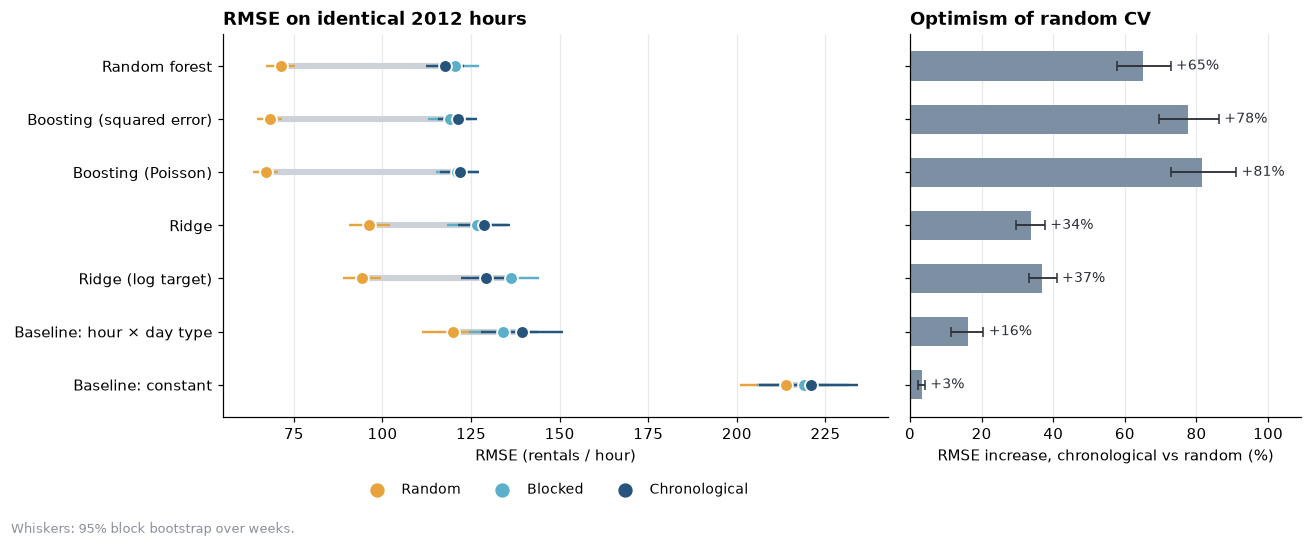

In [9]:
# colour = validation scheme (random is the optimistic one, hence the warm colour)
colors = {"random": "#E8A33D", "blocked": "#5BAFC9", "chrono": "#26547C"}
scheme_names = {"random": "Random", "blocked": "Blocked", "chrono": "Chronological"}

order = rmse_matched["chrono"].sort_values().index.tolist()      # best chronological model at the top
ypos = {m: len(order) - 1 - i for i, m in enumerate(order)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), dpi=110, sharey=True,
                               gridspec_kw={"width_ratios": [1.7, 1]})

for m in order:
    y0 = ypos[m]
    values = [rmse_matched.loc[m, s] for s in SCHEMES]
    ax1.plot([min(values), max(values)], [y0, y0], color="#CDD2D8", lw=4, solid_capstyle="round", zorder=1)
    for s in SCHEMES:
        low, high = np.percentile(boot_rmse[(m, s)], [2.5, 97.5])
        ax1.hlines(y0, low, high, color=colors[s], lw=1.6, zorder=2)
        ax1.scatter(rmse_matched.loc[m, s], y0, s=70, color=colors[s], edgecolor="white", linewidth=1.2, zorder=3)

for s in SCHEMES:                                                 # legend entries
    ax1.scatter([], [], s=70, color=colors[s], label=scheme_names[s])
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False, fontsize=9)
ax1.set_yticks(list(ypos.values()))
ax1.set_yticklabels([NAMES[m] for m in ypos])
ax1.set_xlabel("RMSE (rentals / hour)")
ax1.set_title("RMSE on identical 2012 hours", loc="left", fontweight="bold", fontsize=12)

g = gap.loc[order]
y_pos = [ypos[m] for m in order]
ax2.barh(y_pos, g["gap_pct"], color="#7D8FA3", height=0.55, zorder=2)
ax2.errorbar(g["gap_pct"], y_pos, xerr=[g["gap_pct"] - g["gap_pct_low"], g["gap_pct_high"] - g["gap_pct"]],
             fmt="none", ecolor="#2B2F36", elinewidth=1.2, capsize=3, zorder=3)
for y0, val, high in zip(y_pos, g["gap_pct"], g["gap_pct_high"]):
    ax2.text(high + 1.5, y0, f"{val:+.0f}%", va="center", fontsize=9, color="#2B2F36")
ax2.set_xlabel("RMSE increase, chronological vs random (%)")
ax2.set_xlim(0, g["gap_pct_high"].max() * 1.2)
ax2.set_title("Optimism of random CV", loc="left", fontweight="bold", fontsize=12)

for ax in (ax1, ax2):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#E6E9ED")

fig.text(0.01, -0.02, "Whiskers: 95% block bootstrap over weeks.", fontsize=8.5, color="#8A9099")
plt.tight_layout()
fig.savefig("figures/comparison_matched_rmse.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Error and Residual Diagnostics

All diagnostics use the chronological predictions on the matched 2012 hours, the setting that resembles real forecasting.

### 4.1 Error by test period

Each chronological fold is a different part of 2012 predicted by a model trained on everything before it. The plot shows whether the error is stable across periods or concentrated in some of them (the constant baseline is left out because its scale compresses the rest).

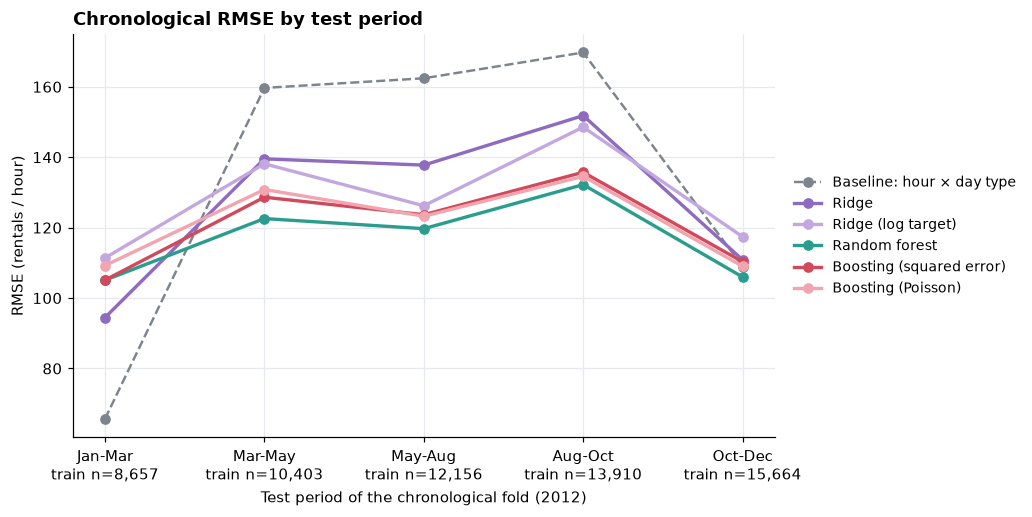

In [10]:
# colour = model (greys for baselines, purple Ridge, green forest, red boosting)
colors = {"baseline_hour_day": "#7D848E", "ridge": "#8E6BBF", "ridge_log": "#C3A8E0",
          "rf": "#2A9D8F", "hgb": "#D1495B", "hgb_poisson": "#F2A5AE"}

f0 = folds[(MODELS[0], "chrono")]
xt_labels = [f"{a:%b}-{b:%b}\ntrain n={n:,}" for a, b, n in zip(f0["test_start"], f0["test_end"], f0["n_train"])]

fig, ax = plt.subplots(figsize=(9.5, 4.8), dpi=110)
for m, color in colors.items():
    is_base = m.startswith("baseline")
    ax.plot(folds[(m, "chrono")]["fold"], folds[(m, "chrono")]["rmse"], marker="o", color=color,
            ls="--" if is_base else "-", lw=1.6 if is_base else 2.2, label=NAMES[m])

ax.set_xticks(f0["fold"])
ax.set_xticklabels(xt_labels)
ax.set_xlabel("Test period of the chronological fold (2012)")
ax.set_ylabel("RMSE (rentals / hour)")
ax.set_title("Chronological RMSE by test period", loc="left", fontweight="bold", fontsize=12)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=9)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.set_axisbelow(True)
ax.grid(color="#E6E9ED")
plt.tight_layout()
fig.savefig("figures/chrono_rmse_by_fold.png", dpi=200, bbox_inches="tight")
plt.show()

### 4.2 Residuals against predictions

Each panel is a density of hours (darker = more hours, log scale); the red line is the mean residual within bins of the predicted value, so it shows whether the model is biased at low or at high predictions. Binning by the *prediction* is the right way to check calibration. (Binning by the *actual* value would mechanically produce positive residuals at high demand and negative at low demand for any noisy model, so it cannot show a model-specific failure.)

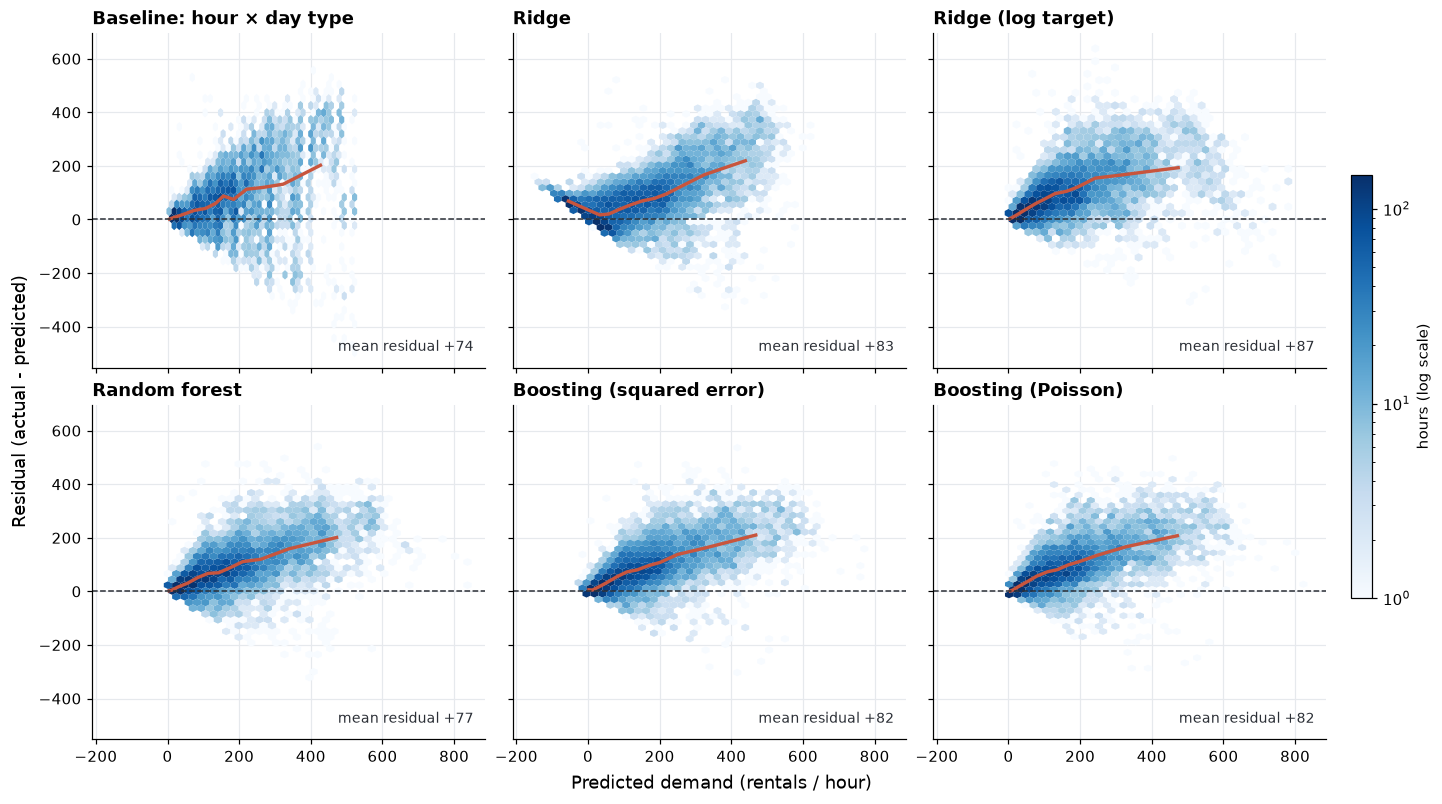

In [11]:
DIAG = ["baseline_hour_day", "ridge", "ridge_log", "rf", "hgb", "hgb_poisson"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7.2), dpi=110, sharex=True, sharey=True, constrained_layout=True)

for ax, m in zip(axes.ravel(), DIAG):
    p = matched[(m, "chrono")]
    res = p["y_true"] - p["y_pred"]
    hb = ax.hexbin(p["y_pred"], res, gridsize=36, mincnt=1, bins="log", cmap="Blues", linewidths=0,
                   vmin=1, vmax=150)
    binned = pd.DataFrame({"x": p["y_pred"], "r": res}).groupby(
        pd.qcut(p["y_pred"], 12, duplicates="drop"), observed=True).mean()
    ax.plot(binned["x"], binned["r"], color="#C8553D", lw=2.2)          # mean residual per prediction bin
    ax.axhline(0, color="#2B2F36", lw=1, ls="--")
    ax.set_title(NAMES[m], loc="left", fontweight="bold", fontsize=12)
    ax.text(0.97, 0.05, f"mean residual {res.mean():+.0f}", transform=ax.transAxes, ha="right",
            fontsize=9, color="#2B2F36")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(color="#E6E9ED")

fig.supxlabel("Predicted demand (rentals / hour)")
fig.supylabel("Residual (actual - predicted)")
fig.colorbar(hb, ax=axes, shrink=0.6, pad=0.02, label="hours (log scale)")
fig.savefig("figures/residuals_vs_predicted.png", dpi=200, bbox_inches="tight")
plt.show()

### 4.3 Bias over time

We examine monthly mean residuals on the chronological 2012 test observations. Positive residuals indicate underestimation of demand, while negative residuals indicate overestimation.

A similar positive bias across the candidate models may indicate a shared temporal change in demand rather than a problem specific to one model family.

However, this pattern should not automatically be attributed to the year-to-year increase in demand. The monthly residuals show an association, not a causal explanation. We therefore distinguish between the five candidate model variants and the baseline models when interpreting the results.

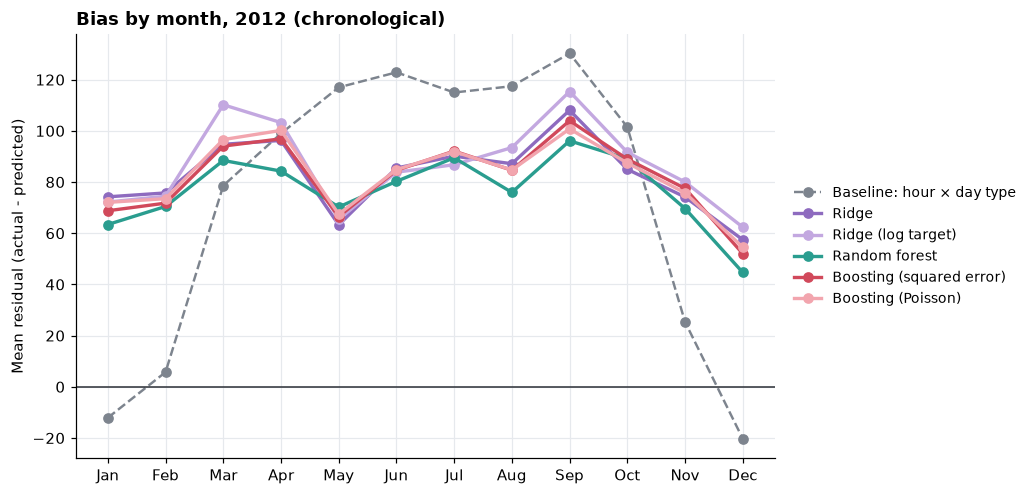

In [12]:
colors = {"baseline_hour_day": "#7D848E", "ridge": "#8E6BBF", "ridge_log": "#C3A8E0",
          "rf": "#2A9D8F", "hgb": "#D1495B", "hgb_poisson": "#F2A5AE"}

fig, ax = plt.subplots(figsize=(9.5, 4.6), dpi=110)
for m, color in colors.items():
    p = matched[(m, "chrono")]
    monthly = (p["y_true"] - p["y_pred"]).resample("MS").mean()
    is_base = m.startswith("baseline")
    ax.plot(monthly.index.month, monthly.values, marker="o", color=color, ls="--" if is_base else "-",
            lw=1.6 if is_base else 2.2, label=NAMES[m])

ax.axhline(0, color="#2B2F36", lw=1)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("Mean residual (actual - predicted)")
ax.set_title("Bias by month, 2012 (chronological)", loc="left", fontweight="bold", fontsize=12)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=9)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.set_axisbelow(True)
ax.grid(color="#E6E9ED")
plt.tight_layout()
fig.savefig("figures/bias_by_month.png", dpi=200, bbox_inches="tight")
plt.show()

### 4.4 Peak versus off-peak hours

We define commuting peak periods as working-day hours 07:00–09:00 and 17:00–19:00. All remaining observations are classified as off-peak.

This definition is based on the daily demand patterns identified during exploratory data analysis and uses calendar features available to the models, rather than selecting observations according to their actual target values.

We compare RMSE and mean residual between the two groups to determine whether prediction errors are larger or more systematically biased during commuting periods.

Peak hours: 1,491 of 8,722 (17%)


rmse            bias       
period            Off-peak   Peak Off-peak   Peak
model                                            
baseline_hour_day    112.6  228.4     55.6  161.0
ridge                103.0  213.1     64.7  169.3
ridge_log            102.9  214.7     68.3  175.1
rf                    89.1  205.9     56.6  174.7
hgb                   93.3  209.3     61.5  180.1
hgb_poisson           93.5  211.1     61.9  182.1

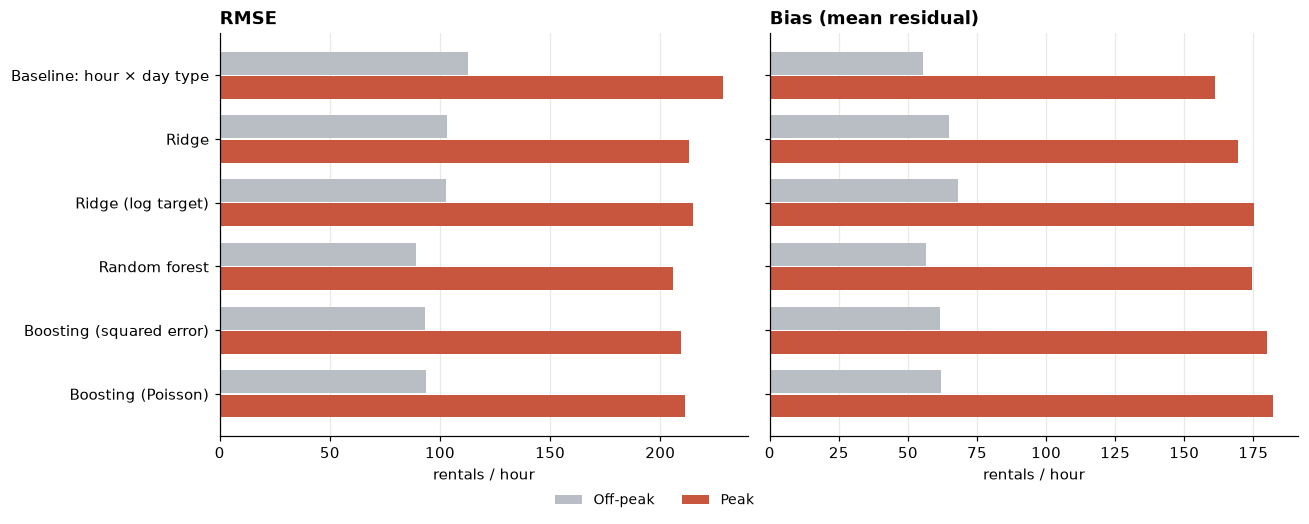

In [13]:
X_all, _ = load_data()
feat = X_all.loc[chrono_index, ["hr", "workingday"]]
is_peak = (feat["hr"].isin([7, 8, 9, 17, 18, 19]) & (feat["workingday"] == 1)).to_numpy()
print(f"Peak hours: {is_peak.sum():,} of {len(is_peak):,} ({is_peak.mean():.0%})")

rows = []
for m in MODELS[1:]:
    p = matched[(m, "chrono")]
    res = (p["y_true"] - p["y_pred"]).to_numpy()
    for period, mask in [("Off-peak", ~is_peak), ("Peak", is_peak)]:
        rows.append({"model": m, "period": period, "rmse": np.sqrt((res[mask] ** 2).mean()), "bias": res[mask].mean()})
peak = pd.DataFrame(rows)
display(peak.pivot(index="model", columns="period", values=["rmse", "bias"]).reindex(MODELS[1:]).round(1))

# colour = period (grey off-peak, accent peak)
period_colors = {"Off-peak": "#B9BEC5", "Peak": "#C8553D"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), dpi=110, sharey=True)
y_idx = np.arange(len(MODELS[1:]))[::-1]
for ax, metric, title in zip(axes, ["rmse", "bias"], ["RMSE", "Bias (mean residual)"]):
    for offset, period in zip([0.19, -0.19], ["Off-peak", "Peak"]):
        vals = peak[peak["period"] == period].set_index("model").loc[MODELS[1:], metric]
        ax.barh(y_idx + offset, vals.values, height=0.36, color=period_colors[period], label=period, zorder=2)
    ax.set_title(title, loc="left", fontweight="bold", fontsize=12)
    ax.set_xlabel("rentals / hour")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#E6E9ED")

axes[0].set_yticks(y_idx)
axes[0].set_yticklabels([NAMES[m] for m in MODELS[1:]])
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout()
fig.savefig("figures/peak_vs_offpeak.png", dpi=200, bbox_inches="tight")
plt.show()

### 4.5 Error by hour of day

Section 4.4 splits hours into two groups. This plot shows the full daily error profile for four representative models: the hour-by-day-type baseline, standard Ridge, Random Forest, and Gradient Boosting with squared-error loss.

The logarithmic Ridge and Poisson Gradient Boosting variants are omitted from this figure to keep it readable; they remain included in the numerical comparisons and other diagnostic plots.

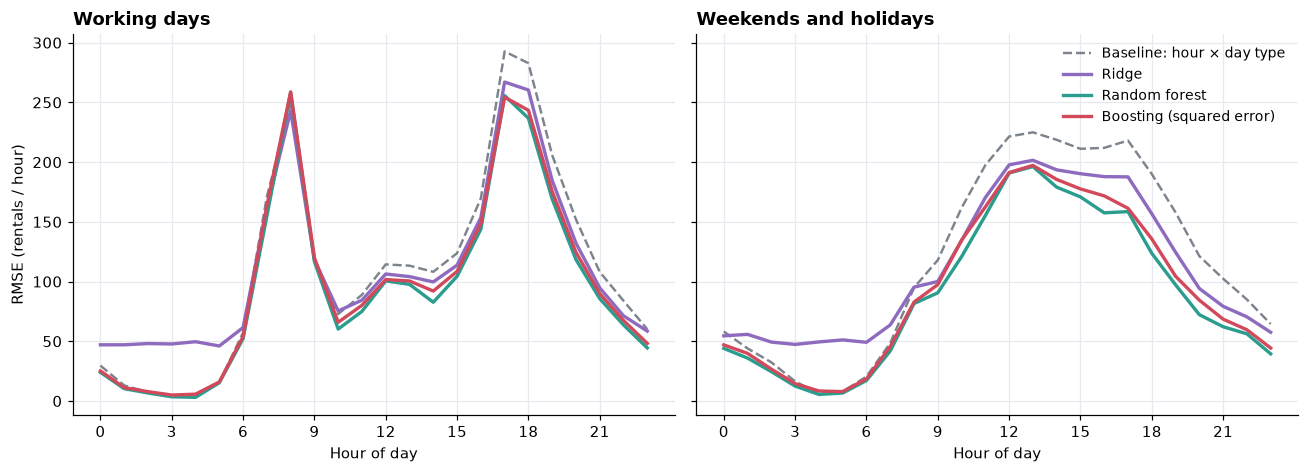

In [14]:
SHOW = ["baseline_hour_day", "ridge", "rf", "hgb"]
MODEL_COLORS = {"baseline_hour_day": "#7D848E", "ridge": "#8E6BBF", "ridge_log": "#C3A8E0",
                "rf": "#2A9D8F", "hgb": "#D1495B", "hgb_poisson": "#F2A5AE"}

feat_all = X_all.loc[chrono_index]
res_df = pd.DataFrame({m: matched[(m, "chrono")]["y_true"] - matched[(m, "chrono")]["y_pred"] for m in MODELS[1:]})
sq = (res_df ** 2).assign(hr=feat_all["hr"].to_numpy(), workingday=feat_all["workingday"].to_numpy())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), dpi=110, sharey=True)
for ax, (wd, title) in zip(axes, [(1, "Working days"), (0, "Weekends and holidays")]):
    rmse_h = np.sqrt(sq[sq["workingday"] == wd].drop(columns="workingday").groupby("hr").mean())
    for m in SHOW:
        ax.plot(rmse_h.index, rmse_h[m], color=MODEL_COLORS[m], lw=1.6 if m.startswith("baseline") else 2.2,
                ls="--" if m.startswith("baseline") else "-", label=NAMES[m])
    ax.set_title(title, loc="left", fontweight="bold", fontsize=12)
    ax.set_xlabel("Hour of day")
    ax.set_xticks(range(0, 24, 3))
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(color="#E6E9ED")
axes[0].set_ylabel("RMSE (rentals / hour)")
axes[1].legend(frameon=False, fontsize=9)
plt.tight_layout()
fig.savefig("figures/rmse_by_hour.png", dpi=200, bbox_inches="tight")
plt.show()

### 4.6 Predicted versus actual demand through 2012

The plot compares weekly mean actual demand with chronological predictions from three representative candidate models: Ridge, Random Forest, and Gradient Boosting.

The dashed line shows Random Forest predictions obtained through random validation on the same 2012 timestamps. This provides a visual illustration of how predictions change when training observations from across the full time period are available, including observations later than the corresponding test timestamps.

The plot helps identify differences in the overall demand level over time. Since it uses weekly averages, it does not show the full hourly prediction error or establish the cause of any observed difference.

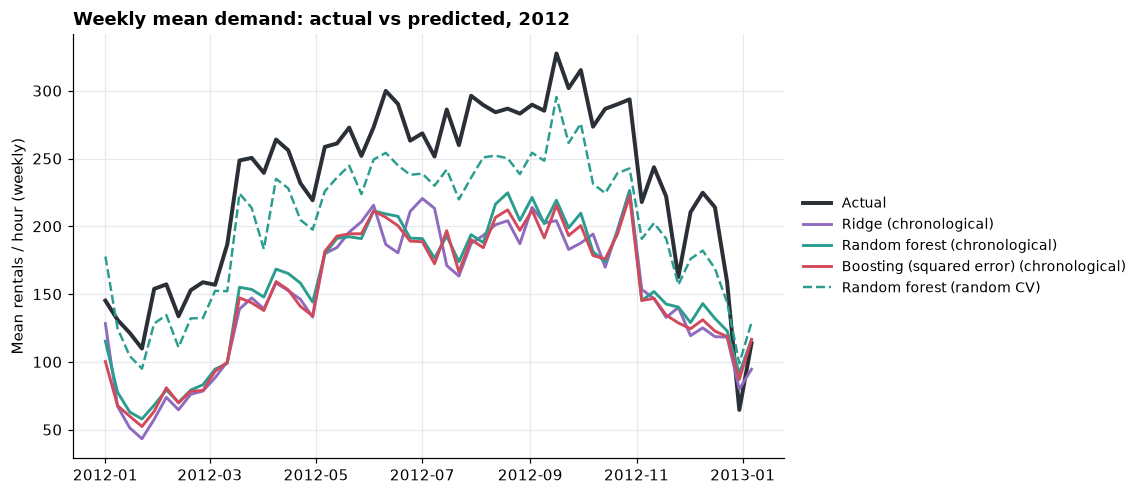

In [15]:
y_true_c = matched[(MODELS[0], "chrono")]["y_true"]
fig, ax = plt.subplots(figsize=(10.5, 4.6), dpi=110)
ax.plot(y_true_c.resample("W").mean(), color="#2B2F36", lw=2.6, label="Actual")
for m in ["ridge", "rf", "hgb"]:
    ax.plot(matched[(m, "chrono")]["y_pred"].resample("W").mean(), color=MODEL_COLORS[m], lw=1.9,
            label=f"{NAMES[m]} (chronological)")
ax.plot(matched[("rf", "random")]["y_pred"].resample("W").mean(), color=MODEL_COLORS["rf"], lw=1.6, ls="--",
        label=f"{NAMES['rf']} (random CV)")
ax.set_ylabel("Mean rentals / hour (weekly)")
ax.set_title("Weekly mean demand: actual vs predicted, 2012", loc="left", fontweight="bold", fontsize=12)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=9)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.set_axisbelow(True)
ax.grid(color="#E6E9ED")
plt.tight_layout()
fig.savefig("figures/weekly_actual_vs_predicted.png", dpi=200, bbox_inches="tight")
plt.show()

### 4.7 The worst days and the worst conditions

An average prediction error can hide whether errors are concentrated in a small number of difficult periods.

We identify the ten days with the highest daily RMSE for the candidate model with the lowest chronological RMSE. We also calculate how much of the total squared prediction error these days account for.

The additional breakdown by weather and holiday conditions is descriptive and helps examine whether prediction errors vary across these groups.

The analysis does not establish that particular weather events, holidays, or disruptions caused the largest errors. Such explanations would require additional external information.

In [16]:
best_model = rmse_matched["chrono"].drop(["baseline_const", "baseline_hour_day"]).idxmin()
p = matched[(best_model, "chrono")]
err = p["y_true"] - p["y_pred"]

daily = pd.DataFrame({"actual": p["y_true"].resample("D").mean(),
                      "predicted": p["y_pred"].resample("D").mean(),
                      "rmse": np.sqrt((err ** 2).resample("D").mean())})
daily["bias"] = daily["actual"] - daily["predicted"]
daily["weekday"] = daily.index.day_name()
worst = daily.sort_values("rmse", ascending=False).head(10)

sq_by_day = (err ** 2).resample("D").sum()
share_top10 = sq_by_day.nlargest(10).sum() / sq_by_day.sum()
print(f"Best chronological model: {NAMES[best_model]}")
print(f"The 10 worst days are {10 / len(daily):.1%} of the days but {share_top10:.1%} of the total squared error")
display(worst.round(1))

Best chronological model: Random forest
The 10 worst days are 2.7% of the days but 6.6% of the total squared error


,actual,predicted,rmse,bias,weekday
datetime,,,,,
2012-03-23,348.4,166.0,234.8,182.4,Friday
2012-10-11,315.4,185.2,183.8,130.2,Thursday
2012-03-17,326.5,188.4,177.5,138.1,Saturday
2012-10-17,310.9,180.2,176.5,130.7,Wednesday
2012-10-16,313.9,183.6,176.3,130.3,Tuesday
2012-04-16,265.4,202.3,175.1,63.1,Monday
2012-09-22,349.8,218.7,174.0,131.1,Saturday
2012-09-29,356.5,223.4,174.0,133.1,Saturday
2012-10-10,320.5,191.3,173.9,129.2,Wednesday


In [17]:
# error by weather / season / holiday for the same model (only the columns that exist in the feature table)
print("Feature columns available:", list(X_all.columns))
cond_cols = [c for c in ("weathersit", "season", "holiday") if c in X_all.columns]
if not cond_cols:
    print("None of weathersit / season / holiday is in the feature table; skip or adapt the column names.")
for col in cond_cols:
    g = pd.DataFrame({"key": X_all.loc[chrono_index, col].to_numpy(), "err": err.to_numpy(),
                      "actual": p["y_true"].to_numpy()})
    g["e2"] = g["err"] ** 2
    grp = g.groupby("key")
    tab = pd.DataFrame({"hours": grp.size(), "mean_actual": grp["actual"].mean(),
                        "rmse": np.sqrt(grp["e2"].mean()), "bias": grp["err"].mean()})
    tab["rmse_rel_to_mean_actual"] = tab["rmse"] / tab["mean_actual"]
    print(f"\n{NAMES[best_model]}: error by {col}")
    display(tab.round(2))

Feature columns available: ['mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed']

Random forest: error by weathersit


,hours,mean_actual,rmse,bias,rmse_rel_to_mean_actual
key,,,,,
1,5756,254.09,122.56,85.01,0.48
2,2326,213.00,109.08,69.60,0.51
3,640,142.22,101.04,28.92,0.71



Random forest: error by holiday


,hours,mean_actual,rmse,bias,rmse_rel_to_mean_actual
key,,,,,
0,8461,236.45,117.75,77.57,0.50
1,261,185.49,113.41,51.51,0.61


## 5. Conclusions and Limitations

### Summary

The experiment shows that the estimated prediction error depends strongly on the validation strategy. On the same 8,722 test observations from 2012, chronological RMSE is higher than random-validation RMSE for all five candidate model variants. The increase ranges from 33.7% for Ridge to 81.5% for Gradient Boosting with Poisson loss.

The size of this difference also depends on the evaluated model implementation. The tree-based models show a substantially larger validation gap than Ridge in these experiments. However, Random Forest achieves the lowest RMSE under chronological validation (117.6), followed by Gradient Boosting with squared error (121.3).

The main shared error pattern among the candidate models is underestimation of demand, particularly during working-day commuting peaks. This is consistent with a change in demand level between 2011 and 2012, although the experiment does not establish this as the sole cause.

### 1. Direction and Size of the Validation Gap

On identical 2012 test observations, random validation produces the lowest RMSE for every candidate model. Chronological RMSE is higher than random RMSE by:

- Ridge: **33.7%** (95% week-bootstrap interval: 29.6%–37.7%).
- Ridge with a log-transformed target: **37.0%** (33.3%–40.9%).
- Random Forest: **65.0%** (57.7%–72.7%).
- Gradient Boosting with squared error: **77.5%** (69.4%–86.2%).
- Gradient Boosting with Poisson loss: **81.5%** (72.8%–91.1%).

The same direction is observed for MAE and RMSLE among the five candidate variants. Their chronological MAE is approximately 38%–98% higher than under random validation, while RMSLE is 18%–59% higher. R² is also lower under chronological validation for every candidate variant.

The direction of the RMSE gap is robust to the bootstrap unit. Resampling calendar days, weeks, or pairs of weeks gives similar point estimates, and the 95% intervals remain above zero for all five candidate variants. The interval widths vary somewhat with the chosen block size.

The decomposition of the RMSE increase shows that most of the difference appears in the transition from random to blocked validation. For the five candidate variants, this first step increases RMSE by approximately 31%–80%. The subsequent blocked-to-chronological change is much smaller, ranging from approximately -5% to +2%.

This pattern is consistent with random splitting benefiting from temporal overlap between training and test observations. However, the decomposition is descriptive and does not isolate a single causal mechanism.

### 2. Dependence of the Validation Gap on the Model

The magnitude of the validation gap differs across the tested model implementations.

The paired bootstrap comparison shows that:

- The Random Forest gap exceeds the Ridge gap by **31.3 percentage points** (95% interval: 25.3–37.8).
- The squared-error Gradient Boosting gap exceeds the Ridge gap by **43.9 percentage points** (37.3–51.4).
- The squared-error Gradient Boosting gap exceeds the Random Forest gap by **12.6 percentage points** (9.3–15.8).
- The Poisson Gradient Boosting gap exceeds the squared-error variant's gap by **4.0 percentage points** (1.8–6.3).

The difference between standard Ridge and log-transformed Ridge is smaller: the log variant has a gap 3.3 percentage points larger, with an interval of 0.06–6.90 percentage points.

These results indicate that the estimated validation gap is associated with the model implementation in this experiment. Random and chronological validation differ more for the tested tree ensembles than for the Ridge variants.

This should not be interpreted as a universal property of linear models and tree ensembles. The comparison includes a limited number of model families and specific preprocessing pipelines, feature representations, target transformations, and hyperparameter grids.

A larger validation gap does not necessarily mean a worse model. Under chronological validation, Random Forest achieves the lowest RMSE among the candidate models. Its RMSE is 15.6% lower than the hour-by-day-type baseline. Under random validation, the estimated improvement appears much larger, at 40.6%.

The same pattern is observed for the other candidates. Their improvements over the hour-by-day-type baseline are:

| Model | Random | Chronological |
|---|---:|---:|
| Ridge | 19.7% | 7.6% |
| Ridge Log | 21.4% | 7.4% |
| Random Forest | 40.6% | 15.6% |
| HGB | 43.1% | 13.0% |
| HGB Poisson | 44.0% | 12.5% |

This shows that random validation overstates the apparent advantage of the candidate models over the baseline.

### 3. What Blocked Validation Shows

Blocked validation produces RMSE values much closer to chronological validation than to random validation for all five candidate variants.

However, blocked validation is not always numerically between random and chronological validation. For Ridge with a log-transformed target and Random Forest, blocked RMSE is higher than chronological RMSE.

The difference between blocked and chronological RMSE is relatively small compared with the much larger difference between random and blocked validation.

This is consistent with the validation design. Blocked validation trains on observations from both before and after its test block, while chronological validation uses only earlier observations. Chronological training windows also differ in size and composition across folds.

Therefore, blocked validation is useful as an additional diagnostic but should not be treated as a substitute for a genuine future-prediction evaluation.

### 4. Main Error Pattern: Systematic Underestimation

All five candidate model variants have a positive mean residual in every month of 2012 under chronological validation. Their overall mean residuals range from approximately +76.8 to +86.6 rentals per hour.

The hour-by-day-type baseline also has positive mean bias over the entire matched test period, although its monthly mean residual becomes slightly negative in at least one month. Therefore, underestimation is a consistent pattern for the candidate models, but not for every model in every individual month.

The weekly actual-versus-predicted plot shows that chronological predictions remain below actual demand during much of 2012. This pattern is consistent with a change in demand level between 2011 and 2012.

Since the main experiments exclude the year indicator and do not use lagged demand, the models cannot directly use these features to represent the year-to-year change. However, the available experiment does not establish the change in demand as the sole cause of the bias.

Even under random validation, all five candidate models have positive average bias on the matched 2012 hours. Random splitting therefore reduces the estimated prediction error but does not eliminate the tendency to underestimate 2012 demand.

### 5. Errors During Peak Hours

Prediction errors are substantially larger during working-day commuting peaks, defined as 07:00–09:00 and 17:00–19:00.

These periods account for approximately 17% of the matched test observations, but their RMSE is approximately 2.0–2.3 times the off-peak RMSE across the evaluated models.

For example, Random Forest has a peak RMSE of 205.9 rentals per hour, compared with 89.1 off-peak. Gradient Boosting with squared error has a peak RMSE of 209.3, compared with 93.3 off-peak.

The mean residual is also much more positive during peak hours, indicating stronger underestimation when demand is high. This suggests that the models capture general temporal patterns but struggle to predict the magnitude of commuting peaks.

### 6. Concentration of Errors on Particular Days

For the best chronological candidate model, Random Forest, the ten days with the highest daily RMSE account for 6.6% of the total squared prediction error, while representing 2.7% of the test days.

This indicates some concentration of errors on difficult days, but the majority of the squared error is distributed across the remaining period. The available features do not establish whether particular events, disruptions, or other external factors caused the largest errors.

### 7. Practical Implications

For this dataset and these model configurations, random k-fold cross-validation gives a substantially more optimistic estimate of predictive performance than chronological validation.

The difference is especially large for the tree-based models. Random validation also exaggerates their apparent improvement over the hour-by-day-type baseline.

For a task intended to predict future hourly demand, chronological validation should therefore be used as the primary evaluation scheme. Blocked validation provides additional information about performance on contiguous time periods, but it allows future observations in training and does not reproduce a forecasting setting.

Among the candidate models, Random Forest achieves the lowest chronological RMSE (117.6 rentals per hour). Its advantage over Gradient Boosting is relatively modest. The current bootstrap analysis compares validation gaps rather than directly testing differences in absolute model RMSE, so the ranking should not be interpreted as proof of a statistically significant difference between these two models.

### 8. Limitations

- The dataset covers only two years and one city. The findings should not be generalised to all bike-sharing systems or forecasting tasks.
- Chronological validation tests on 2012, which contains a change in demand level relative to 2011. The size of the validation gap may differ in periods without such a shift.
- Random and blocked validation may use future observations relative to test timestamps. Their results are diagnostic comparisons, not realistic simulations of future forecasting.
- The matched evaluation holds test timestamps constant, but training sets remain different across validation schemes. The comparison therefore reflects both the validation design and the amount and temporal composition of training data.
- The bootstrap intervals quantify sensitivity to the sampled test periods conditional on the saved out-of-fold predictions. They do not include the full uncertainty from model training, random splitting, or hyperparameter selection.
- The validation-gap comparison uses one fixed random seed and a limited number of model implementations. The results provide evidence about these experiments, not a universal ranking of model architectures.
- The overall best-performing candidate is identified using the same chronological out-of-fold results used for model comparison. No separate untouched test period is reserved for evaluating the selected model after model selection, so the reported ranking should be interpreted as an empirical comparison within this experiment rather than an independent final performance estimate.
- The hyperparameter grids are finite and relatively coarse. Some selected values lie on the boundaries of the tested grids.
- Potential improvements such as adding year information, lagged demand, or detrending were not evaluated.

Overall, the experiment demonstrates that validation strategy can substantially change the estimated performance of hourly demand prediction models. The results support chronological validation for assessing future-prediction performance and show that the apparent advantage of flexible models can be strongly overstated by random cross-validation.

## 6. Reproducibility Record

This section exports the main comparison tables and selected diagnostic results for future reference and records the versions of the main libraries used in the analysis.

The saved files allow the key numerical results to be inspected without reconstructing the entire comparison from the original out-of-fold prediction files.

In [18]:
import platform, sys
import matplotlib

OUT = RESULTS_DIR / "summary"
OUT.mkdir(exist_ok=True)
summary_wide.to_csv(OUT / "fold_averaged_summary.csv")
df_matched.to_csv(OUT / "matched_2012_metrics.csv", index=False)
gap.to_csv(OUT / "rmse_gap_week_bootstrap.csv")
gap_all.to_csv(OUT / "gap_all_metrics.csv", index=False)
decomp.to_csv(OUT / "gap_decomposition.csv", index=False)
family.to_csv(OUT / "gap_family_comparison.csv", index=False)
gain_ci.to_csv(OUT / "gain_over_baseline.csv")
worst.to_csv(OUT / "worst_days.csv")
print("Saved:", sorted(p.name for p in OUT.iterdir()))

versions = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
            "matplotlib": matplotlib.__version__}
try:
    import sklearn
    versions["scikit-learn"] = sklearn.__version__
except ImportError:
    pass
print("SEED =", SEED, "| N_BOOT =", N_BOOT)
print(versions)

Saved: ['fold_averaged_summary.csv', 'gain_over_baseline.csv', 'gap_all_metrics.csv', 'gap_decomposition.csv', 'gap_family_comparison.csv', 'matched_2012_metrics.csv', 'rmse_gap_week_bootstrap.csv', 'worst_days.csv']
SEED = 42 | N_BOOT = 2000
{'python': '3.13.2', 'numpy': '2.5.4', 'pandas': '3.1.0', 'matplotlib': '3.11.2', 'scikit-learn': '1.9.1'}
